# Behavioral ML: learning from portal-interaction features

**Portfolio methods demonstration, fully synthetic data.**

> **Synthetic data only.** The dataset is artificial (hand-designed distributions) and mirrors only the column structure of a confidential research dataset. It contains no participant records, and no number here is a finding about real behavior or a validation of the original instrument. See the README for details.

**Aim:** demonstrate a defensible ML workflow for repeated-measures behavioral data: data validation, redundancy and leakage audits, participant-grouped validation, baseline comparisons, hyperparameter search, a label-permutation test, uncertainty estimates that respect the participant structure, error inspection, and unsupervised exploration. High accuracy is neither expected nor the goal.

## 1. Setup and data audit

Run from the repository root or from `notebooks/`. If needed, regenerate the CSV with `python src/generate_synthetic_data.py`.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             brier_score_loss, classification_report, ConfusionMatrixDisplay, silhouette_score)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

SEED = 2026
ROOT = Path.cwd()
if not (ROOT / 'data' / 'synthetic_portal_trials.csv').exists():
    ROOT = Path.cwd().parent
DATA_PATH = ROOT / 'data' / 'synthetic_portal_trials.csv'
assert DATA_PATH.exists(), f'Run from the repository root or notebooks folder. Missing: {DATA_PATH}'
df = pd.read_csv(DATA_PATH)
print(f'Synthetic dataset: {df.shape[0]} trials, {df.shape[1]} fields, {df.participant.nunique()} artificial participants')
print('Phases:', df.phase.value_counts().to_dict())
display(df[['participant','phase','total_looks','normalized_entropy','success']].head())

Synthetic dataset: 384 trials, 72 fields, 24 artificial participants
Phases: {'AssociationTraining': 216, 'StoryMode': 120, 'ThreePortalPractice': 48}


,participant,phase,total_looks,normalized_entropy,success
0,S01,StoryMode,17,0.770395,0
1,S01,StoryMode,23,0.897126,1
2,S01,AssociationTraining,15,0.441552,1
3,S01,AssociationTraining,14,0.914101,1
4,S01,AssociationTraining,19,0.599038,1


In [2]:
# Lightweight consistency assertions: fail loudly if the schema or arithmetic breaks.
required = {'participant','phase','success','is_valid_trial','n_available_portals','total_looks','latency_s','normalized_entropy'}
assert required.issubset(df.columns)
assert df['success'].isin([0,1]).all()
assert df['participant'].nunique() > 10
assert np.allclose(df['total_looks'], df[['looks_portal_0','looks_portal_1','looks_portal_2']].sum(axis=1))
assert np.allclose(df['total_portal_gaze_s'], df[['dwell_portal_0_s','dwell_portal_1_s','dwell_portal_2_s']].sum(axis=1))
assert (df['total_portal_gaze_s'] <= df['latency_s']).all()
print('Schema and arithmetic checks passed.')

# Columns with any missing values, across the whole file.
missing = df.isna().sum()
display(missing[missing > 0].rename('n_missing').to_frame())

# The missingness pattern of one column is itself a leak: it is undefined exactly when the trial failed.
assert df['efficiency_success_only'].isna().eq(df['success'].eq(0)).all()
print("'efficiency_success_only' is missing exactly on unsuccessful trials, so it encodes the label.")

Schema and arithmetic checks passed.
'efficiency_success_only' is missing exactly on unsuccessful trials, so it encodes the label.


,n_missing
efficiency_success_only,136


## 2. Define the prediction question, prevent leakage, audit redundancy

**Demonstration task:** classify trial success from aggregate behavioral measurements in a **single phase** (`AssociationTraining`), with generalization to **unseen synthetic participants**. This is a retrospective *end-of-observation* classifier, **not** an intervention-time predictor.

**Leakage.** `decision_efficiency`, `efficiency_success_only` and `decision_efficiency_cost_adjusted` are computed from `success` itself, which is direct target leakage. Choice-relative metrics (`chosen_*`, `chosen_minus_*`) depend on the eventual choice and are excluded so that the prediction timing stays unambiguous. Participant identifiers and timestamps are not predictors.

**Redundancy.** Before choosing features I check which candidates are exact functions of others. Redundant inputs inflate the apparent feature count, make logistic coefficients unstable, and split permutation importance between interchangeable columns. The cell below asserts the identities instead of just noting a high correlation.

Rows dropped by the validity filter: 0
total_reentries = total_looks - num_unique_portals        (exact)
search_cost     = total_looks + total_reentries            (exact)

Using 9 of 11 candidates; dropped ['total_reentries', 'search_cost'].


,feature_a,feature_b,spearman_rho
0,total_looks,search_cost,1.00
1,total_reentries,search_cost,1.00
2,total_looks,total_reentries,0.99
3,total_portal_gaze_s,max_dwell_s,0.95
4,normalized_entropy,max_look_prop,-0.91
5,log_latency_s,total_portal_gaze_s,0.84
6,log_latency_s,max_dwell_s,0.80
7,total_reentries,max_look_count,0.75
8,max_look_count,search_cost,0.74
9,total_looks,max_look_count,0.71


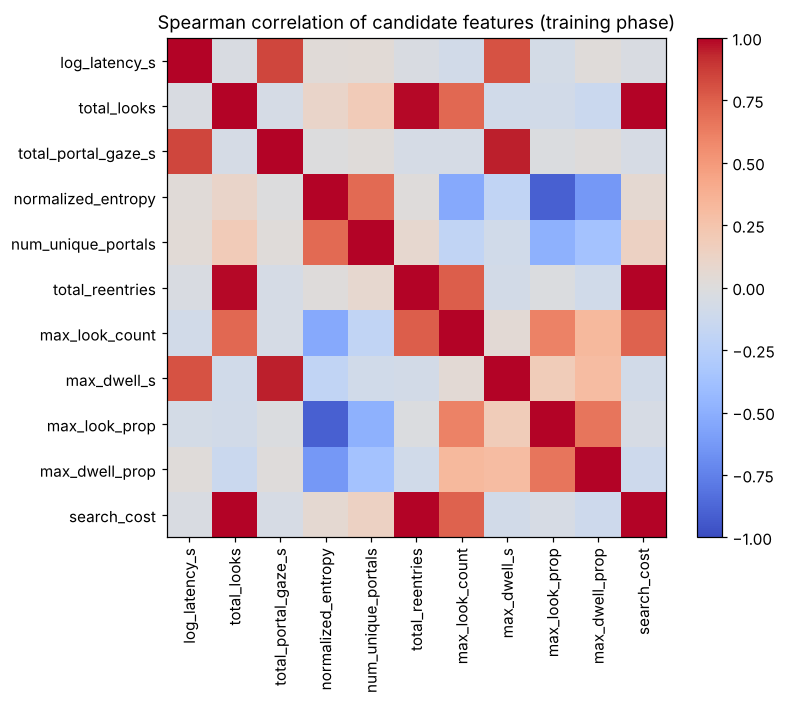

In [3]:
candidate_features = [
    'log_latency_s', 'total_looks', 'total_portal_gaze_s',
    'normalized_entropy', 'num_unique_portals', 'total_reentries',
    'max_look_count', 'max_dwell_s', 'max_look_prop', 'max_dwell_prop',
    'search_cost'
]
in_phase = df['phase'] == 'AssociationTraining'
print('Rows dropped by the validity filter:', int((in_phase & (df['is_valid_trial'] != True)).sum()))
trial_df = df.loc[in_phase & (df['is_valid_trial'] == True)].copy()

# Exact algebraic identities among candidates (asserted, not assumed).
assert (trial_df['total_reentries'] == trial_df['total_looks'] - trial_df['num_unique_portals']).all()
assert (trial_df['search_cost'] == trial_df['total_looks'] + trial_df['total_reentries']).all()
print('total_reentries = total_looks - num_unique_portals        (exact)')
print('search_cost     = total_looks + total_reentries            (exact)')

corr = trial_df[candidate_features].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, fraction=.046)
ax.set_title('Spearman correlation of candidate features (training phase)')
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = upper.rename('spearman_rho').reset_index()
pairs.columns = ['feature_a', 'feature_b', 'spearman_rho']
display(pairs.loc[pairs.spearman_rho.abs() > .7].sort_values('spearman_rho', key=abs, ascending=False).round(2).reset_index(drop=True))

# Drop the two features that are deterministic functions of the others.
redundant = ['total_reentries', 'search_cost']
features = [f for f in candidate_features if f not in redundant]
print(f'\nUsing {len(features)} of {len(candidate_features)} candidates; dropped {redundant}.')

216 synthetic training-phase trials from 24 participant IDs
Trials per participant: {'min': 9, 'max': 9}
Missing entries in selected features: 0
Synthetic class proportions:
 success
1    0.611
0    0.389


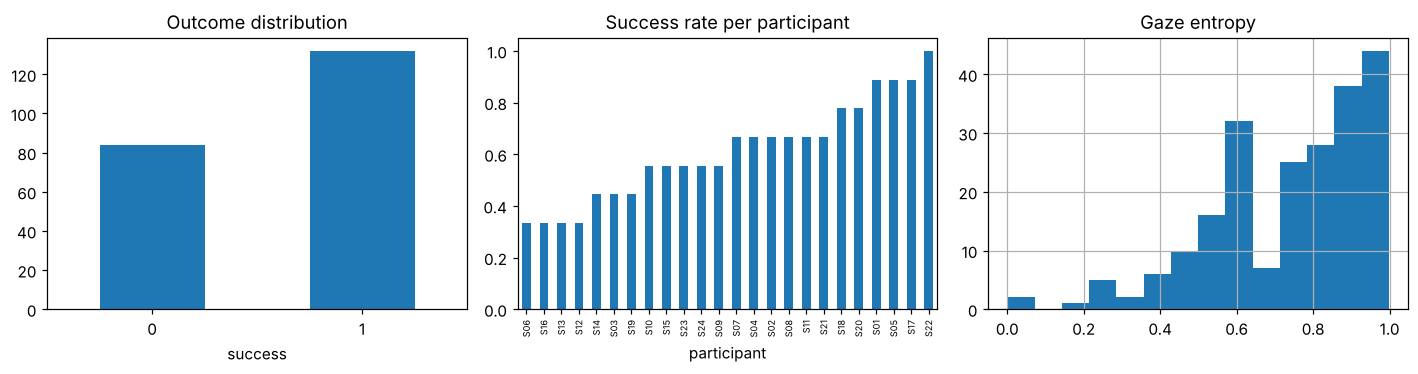

In [4]:
X = trial_df[features]
y = trial_df['success'].astype(int)
groups = trial_df['participant']
assert len(X) > 100 and groups.nunique() > 10
assert X.isna().sum().sum() == 0, 'Unexpected missing values in selected features'
print(f'{len(X)} synthetic training-phase trials from {groups.nunique()} participant IDs')
print('Trials per participant:', groups.value_counts().agg(['min', 'max']).to_dict())
print('Missing entries in selected features:', int(X.isna().sum().sum()))
print('Synthetic class proportions:\n', y.value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
y.value_counts().sort_index().plot.bar(ax=axes[0], title='Outcome distribution', rot=0)
trial_df.groupby('participant')['success'].mean().sort_values().plot.bar(ax=axes[1], title='Success rate per participant')
axes[1].tick_params(axis='x', labelsize=6)
trial_df['normalized_entropy'].hist(ax=axes[2], bins=14)
axes[2].set_title('Gaze entropy')
plt.tight_layout(); plt.show()

The middle panel is the reason for grouped validation: success rates differ a lot between participants, so a random row split would let a model learn *who* a trial belongs to and not what the behavior means.

## 3. Group-disjoint holdout, baselines and repeated grouped CV

All trials belonging to a participant stay in the same partition. I use a fixed **group holdout** that is reserved until model selection is finished, and I run all model comparison with **grouped CV inside the training participants only**.

The comparison includes a prior (majority-class) baseline, a **two-feature logistic model** (entropy and latency, chosen a priori) to show whether the richer models add anything over something a reader can hold in their head, and a gradient-boosting model. Because the cohort is small, one CV split is noisy, so each model is scored over **5 repeats of 4-fold grouped CV**. The SD across those 20 folds is descriptive only, since folds share participants and are not independent.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test))
print('Participants train/test:', g_train.nunique(), g_test.nunique())
print('Trials train/test:', len(X_train), len(X_test))
print('Positive-class rate train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

def scores(y_true, pred, proba=None):
    out = {'accuracy': accuracy_score(y_true, pred),
           'balanced_accuracy': balanced_accuracy_score(y_true, pred),
           'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0)}
    if proba is not None:
        out['roc_auc'] = roc_auc_score(y_true, proba) if len(np.unique(y_true)) == 2 else np.nan
        out['brier'] = brier_score_loss(y_true, proba)   # lower is better
    return out

TWO_FEATURES = ['normalized_entropy', 'log_latency_s']   # fixed a priori, not selected on any score

def make_models():
    prep = lambda: [('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]
    return {
        'Prior (majority-class) baseline': DummyClassifier(strategy='prior'),
        'Logistic, 2 features': Pipeline(
            [('select', ColumnTransformer([('keep', 'passthrough', TWO_FEATURES)], remainder='drop'))]
            + prep() + [('model', LogisticRegression(max_iter=1000, random_state=SEED))]),
        'Logistic, all features': Pipeline(
            prep() + [('model', LogisticRegression(max_iter=1000, random_state=SEED))]),
        'Random forest': Pipeline(
            [('impute', SimpleImputer(strategy='median')),
             ('model', RandomForestClassifier(n_estimators=180, min_samples_leaf=4, random_state=SEED, n_jobs=-1))]),
        'Gradient boosting': HistGradientBoostingClassifier(
            max_depth=3, learning_rate=.05, max_iter=120, min_samples_leaf=10, random_state=SEED),
    }

N_REPEATS = 5
def repeated_group_cv(est, X, y, g, n_splits=4, n_repeats=N_REPEATS):
    rows = []
    for r in range(n_repeats):
        cv_r = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED + r)
        for k, (it, iv) in enumerate(cv_r.split(X, y, g)):
            m = clone(est).fit(X.iloc[it], y.iloc[it])
            rows.append({'repeat': r, 'fold': k,
                         **scores(y.iloc[iv], m.predict(X.iloc[iv]), m.predict_proba(X.iloc[iv])[:, 1])})
    return pd.DataFrame(rows)

cv_summary = []
for name, est in make_models().items():
    res = repeated_group_cv(est, X_train, y_train, g_train)
    cv_summary.append({'model': name,
                       'macro_f1_mean': res.macro_f1.mean(), 'macro_f1_sd': res.macro_f1.std(),
                       'roc_auc_mean': res.roc_auc.mean(), 'roc_auc_sd': res.roc_auc.std(),
                       'brier_mean': res.brier.mean()})
display(pd.DataFrame(cv_summary).set_index('model').round(3))

Participants train/test: 18 6
Trials train/test: 162 54
Positive-class rate train/test: 0.623 0.574


,macro_f1_mean,macro_f1_sd,roc_auc_mean,roc_auc_sd,brier_mean
model,,,,,
Prior (majority-class) baseline,0.383,0.018,0.500,0.000,0.237
"Logistic, 2 features",0.449,0.049,0.555,0.043,0.235
"Logistic, all features",0.443,0.039,0.518,0.043,0.246
Random forest,0.469,0.069,0.559,0.083,0.246
Gradient boosting,0.484,0.060,0.529,0.075,0.284


## 4. Hyperparameter search (training groups only)

A modest randomized search shows how to tune an estimator without touching the holdout. The target is macro-F1 rather than raw accuracy because the classes are unbalanced. The search is intentionally small so it runs on a laptop, and the grouped splitter receives `groups`, so no participant straddles a fold.

In [6]:
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
rf_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                    ('model', RandomForestClassifier(random_state=SEED, n_jobs=-1))])
search = RandomizedSearchCV(
    rf_pipe,
    param_distributions={'model__n_estimators': [80, 140, 220],
                         'model__max_depth': [3, 5, None],
                         'model__min_samples_leaf': [2, 4, 8],
                         'model__max_features': ['sqrt', .7]},
    n_iter=10, scoring='f1_macro', cv=cv, random_state=SEED, n_jobs=-1, refit=True
)
search.fit(X_train, y_train, groups=g_train)
print('Best grouped CV macro-F1:', round(search.best_score_, 3))
print('Chosen settings:', search.best_params_)
top = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(5)
display(top[['rank_test_score', 'mean_test_score', 'std_test_score'] + [c for c in top.columns if c.startswith('param_')]].round(3))

Best grouped CV macro-F1: 0.514
Chosen settings: {'model__n_estimators': 140, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}


,rank_test_score,mean_test_score,std_test_score,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth
7,1,0.514,0.040,140,2,sqrt,None
1,2,0.488,0.025,220,2,sqrt,None
5,3,0.474,0.007,80,2,0.7,None
3,4,0.465,0.045,140,2,sqrt,5
0,5,0.451,0.043,140,2,0.7,3


## 5. Is the signal distinguishable from chance? (label-permutation test)

A cross-validated score always looks like *something*, so I ask how often a model scores this well when the features carry no information about the outcome. The null is built by **shuffling `success` within each participant**, which keeps every participant's base rate (the strongest non-feature signal in this data) while breaking the link between behavior and outcome. The same grouped CV is rerun for every shuffle.

To avoid selection bias I use the **untuned** random forest here: its hyperparameters were not chosen on these folds, so the observed score and the null are directly comparable. Only training participants are used, so the holdout stays untouched. The p-value is `(1 + #null >= observed) / (1 + n_perm)`.

Observed grouped-CV macro-F1: 0.469
Null (within-participant shuffles): mean 0.477, 95th percentile 0.550
Permutation p-value (n_perm=100): 0.594


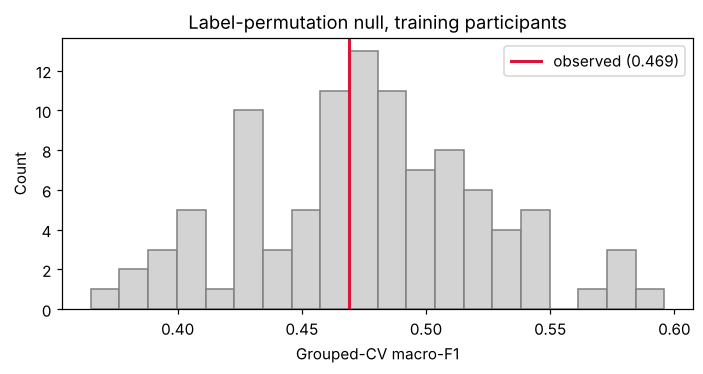

In [7]:
def grouped_cv_macro_f1(est, X, y, g, cv_obj):
    s = []
    for it, iv in cv_obj.split(X, y, g):
        m = clone(est).fit(X.iloc[it], y.iloc[it])
        s.append(f1_score(y.iloc[iv], m.predict(X.iloc[iv]), average='macro', zero_division=0))
    return float(np.mean(s))

def permute_within_participants(y, g, rng):
    y_arr, g_arr = y.to_numpy().copy(), g.to_numpy()
    for pid in np.unique(g_arr):
        idx = np.flatnonzero(g_arr == pid)
        y_arr[idx] = rng.permutation(y_arr[idx])
    return pd.Series(y_arr, index=y.index)

N_PERM = 100
perm_est = make_models()['Random forest']
perm_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
observed = grouped_cv_macro_f1(perm_est, X_train, y_train, g_train, perm_cv)

rng = np.random.default_rng(SEED)
null = np.array([grouped_cv_macro_f1(perm_est, X_train, permute_within_participants(y_train, g_train, rng), g_train, perm_cv)
                 for _ in range(N_PERM)])
p_value = (1 + np.sum(null >= observed)) / (1 + N_PERM)

print(f'Observed grouped-CV macro-F1: {observed:.3f}')
print(f'Null (within-participant shuffles): mean {null.mean():.3f}, 95th percentile {np.percentile(null, 95):.3f}')
print(f'Permutation p-value (n_perm={N_PERM}): {p_value:.3f}')
plt.figure(figsize=(6.5, 3.5))
plt.hist(null, bins=20, color='lightgray', edgecolor='gray')
plt.axvline(observed, color='crimson', lw=2, label=f'observed ({observed:.3f})')
plt.xlabel('Grouped-CV macro-F1'); plt.ylabel('Count'); plt.title('Label-permutation null, training participants')
plt.legend(); plt.tight_layout(); plt.show()

## 6. One-time holdout evaluation, uncertainty and error analysis

The tuned random forest was designated the primary model before the holdout was opened. The other models are shown for context only, and the holdout is inspected once as a methodological demonstration.

The holdout contains only a handful of participants, so a point estimate would be misleading on its own. I report **participant-level (cluster) bootstrap 95% intervals**: whole participants are resampled with replacement, which respects the within-person dependence that a row-level bootstrap would ignore. Expect wide intervals; their width is the point.

In [8]:
final = make_models()
for name, m in final.items():
    m.fit(X_train, y_train)
final['Tuned random forest'] = search.best_estimator_      # already refit on the training participants
primary = 'Tuned random forest'

preds = {n: (m.predict(X_test), m.predict_proba(X_test)[:, 1]) for n, m in final.items()}

test_g = g_test.to_numpy(); y_t = y_test.to_numpy()
pids = np.unique(test_g)
rows_by_pid = {p: np.flatnonzero(test_g == p) for p in pids}
boot_rng = np.random.default_rng(SEED)
B = 1000
boot_idx = [np.concatenate([rows_by_pid[p] for p in boot_rng.choice(pids, size=len(pids), replace=True)]) for _ in range(B)]

def boot_interval(pred, proba):
    f1s, aucs = [], []
    for idx in boot_idx:
        yt = y_t[idx]
        f1s.append(f1_score(yt, pred[idx], average='macro', zero_division=0))
        if len(np.unique(yt)) == 2:
            aucs.append(roc_auc_score(yt, proba[idx]))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(aucs, [2.5, 97.5])

table = []
for name, (pred, proba) in preds.items():
    s = scores(y_test, pred, proba)
    (f_lo, f_hi), (a_lo, a_hi) = boot_interval(pred, proba)
    table.append({'model': name,
                  'accuracy': round(s['accuracy'], 3),
                  'balanced_accuracy': round(s['balanced_accuracy'], 3),
                  'macro_f1 [95% CI]': f"{s['macro_f1']:.3f} [{f_lo:.2f}, {f_hi:.2f}]",
                  'roc_auc [95% CI]': f"{s['roc_auc']:.3f} [{a_lo:.2f}, {a_hi:.2f}]",
                  'brier': round(s['brier'], 3)})
print(f'Holdout: {len(pids)} participants, {len(y_test)} trials; {B} participant-level bootstrap resamples')
display(pd.DataFrame(table).set_index('model'))

Holdout: 6 participants, 54 trials; 1000 participant-level bootstrap resamples


,accuracy,balanced_accuracy,macro_f1 [95% CI],roc_auc [95% CI],brier
model,,,,,
Prior (majority-class) baseline,0.574,0.500,"0.365 [0.31, 0.42]","0.500 [0.50, 0.50]",0.247
"Logistic, 2 features",0.630,0.576,"0.538 [0.39, 0.69]","0.655 [0.56, 0.76]",0.229
"Logistic, all features",0.556,0.506,"0.467 [0.38, 0.56]","0.537 [0.41, 0.69]",0.248
Random forest,0.593,0.561,"0.553 [0.38, 0.68]","0.638 [0.52, 0.75]",0.230
Gradient boosting,0.500,0.480,"0.478 [0.33, 0.60]","0.572 [0.43, 0.72]",0.261
Tuned random forest,0.667,0.637,"0.635 [0.52, 0.73]","0.640 [0.51, 0.77]",0.233


Classwise evaluation on synthetic holdout (primary model):
              precision    recall  f1-score   support

           0       0.67      0.43      0.53        23
           1       0.67      0.84      0.74        31

    accuracy                           0.67        54
   macro avg       0.67      0.64      0.63        54
weighted avg       0.67      0.67      0.65        54



,n_trials,accuracy,observed_success_rate
participant,,,
S04,9,0.78,0.67
S15,9,0.78,0.56
S16,9,0.67,0.33
S17,9,0.78,0.89
S19,9,0.56,0.44
S24,9,0.44,0.56


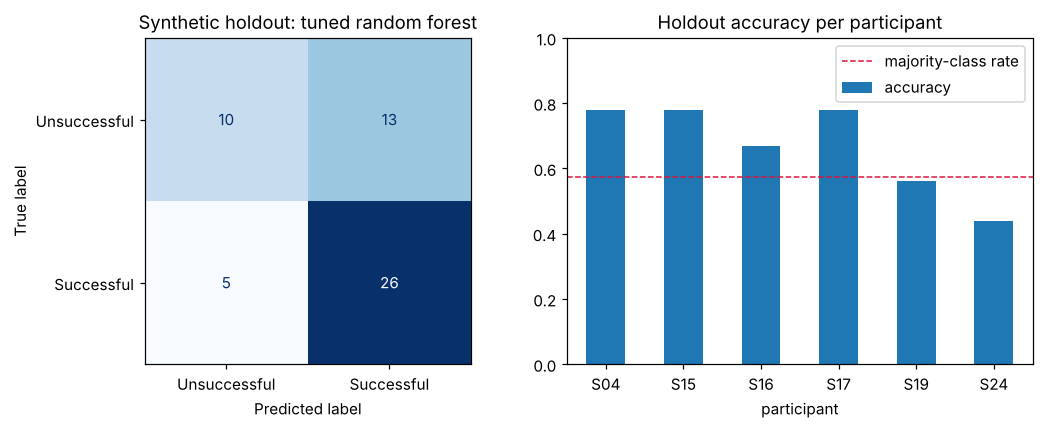

In [9]:
pred_p, proba_p = preds[primary]
print('Classwise evaluation on synthetic holdout (primary model):')
print(classification_report(y_test, pred_p, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_p, display_labels=['Unsuccessful', 'Successful'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Synthetic holdout: tuned random forest')

# Error inspection: are mistakes spread evenly, or concentrated in a few participants?
err = (pd.DataFrame({'participant': g_test.to_numpy(), 'correct': (pred_p == y_t).astype(int), 'success': y_t})
       .groupby('participant').agg(n_trials=('correct', 'size'), accuracy=('correct', 'mean'), observed_success_rate=('success', 'mean'))
       .round(2))
display(err)
err['accuracy'].plot.bar(ax=axes[1], title='Holdout accuracy per participant', rot=0, ylim=(0, 1))
axes[1].axhline(max(y_test.mean(), 1 - y_test.mean()), color='crimson', ls='--', lw=1, label='majority-class rate')
axes[1].legend(); plt.tight_layout(); plt.show()

**Reading these results (fixed seed, so these statements refer to the committed run; re-check them if you regenerate the data or change `SEED`).**

- The label-permutation test (section 5) does not separate the untuned random forest from the shuffled-label null, so the grouped-CV evidence for any real signal is weak. That is the expected outcome for a deliberately weak synthetic dataset, and the test is what makes it visible.
- On the holdout, the tuned random forest has the highest point estimates, but its bootstrap intervals overlap those of the simpler models and of chance-level AUC. Its CV score from the search (section 4) is also optimistic because the settings were selected on those folds. The two-feature logistic model is hard to distinguish from it.
- Per-participant accuracy varies, and with only six holdout participants a single participant moves the aggregate noticeably. Treat any ranking of models here as illustrative.

## 7. Permutation importance on held-out synthetic participants

Permutation importance measures how much the score drops when one feature is shuffled. It is not a causal effect. Correlated features share importance, and when performance is near baseline the ranking is unstable, so the error bars (SD over 10 shuffles) matter more than the order. Bars that cross zero are indistinguishable from noise.

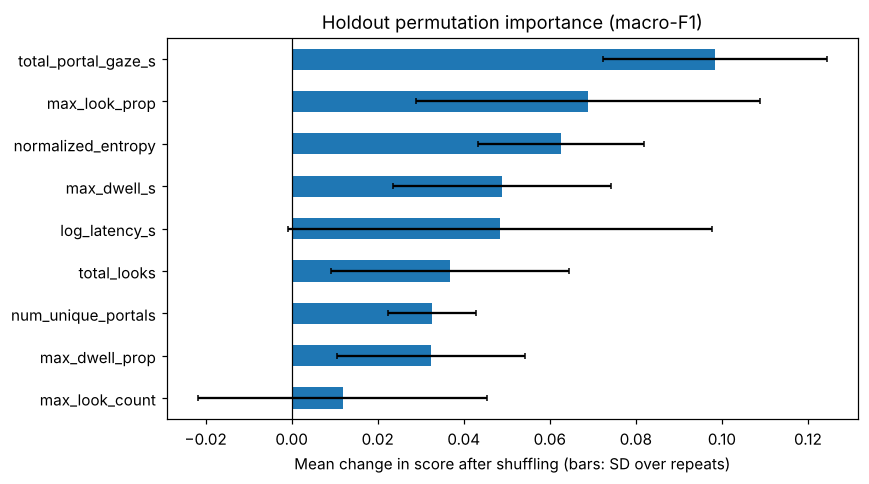

In [10]:
imp = permutation_importance(final[primary], X_test, y_test, scoring='f1_macro', n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({'mean': imp.importances_mean, 'sd': imp.importances_std}, index=features).sort_values('mean')
ax = importance['mean'].plot.barh(xerr=importance['sd'], figsize=(8, 4.5), title='Holdout permutation importance (macro-F1)', capsize=2)
ax.axvline(0, color='k', lw=.8)
plt.xlabel('Mean change in score after shuffling (bars: SD over repeats)'); plt.tight_layout(); plt.show()

## 8. Unsupervised exploration (separate question)

Clustering asks whether the synthetic gaze and exploration measurements have geometric groupings, **not** whether they reveal verified behavioral strategies. Preprocessing, PCA and K-means are fit on the training participants only; holdout trials are then **projected and assigned** with the fitted objects. `k` is chosen from the training silhouette scores in code instead of being hard-coded, and `total_reentries` is left out because it is almost perfectly collinear with `total_looks` and would double-weight one behavior in the distance metric. Every participant contributes the same number of trials in this phase, so no participant dominates the clusters.

Selected k = 2 (highest training silhouette = 0.272)
Out-of-sample silhouette on holdout trials: 0.278
Rule of thumb (Kaufman & Rousseeuw): silhouette below ~0.25 suggests no substantial cluster structure.


,train silhouette
k,
2,0.272
3,0.224
4,0.225
5,0.227


,train,holdout
cluster,,
0,65,22
1,97,32


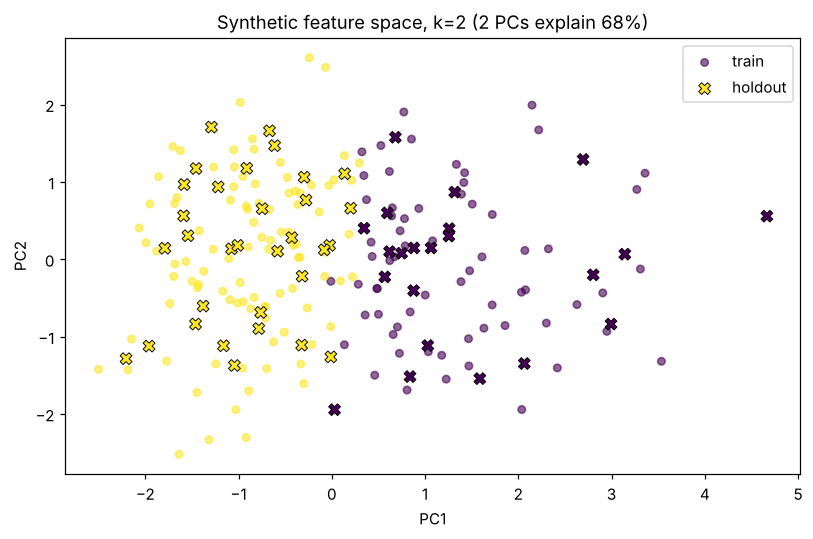

In [11]:
unsup_features = ['total_looks', 'normalized_entropy', 'max_dwell_prop', 'log_latency_s']
prep_u = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]).fit(X_train[unsup_features])
Xu_train, Xu_test = prep_u.transform(X_train[unsup_features]), prep_u.transform(X_test[unsup_features])
pca = PCA(n_components=2, random_state=SEED).fit(Xu_train)
coords_train, coords_test = pca.transform(Xu_train), pca.transform(Xu_test)

sil = {k: silhouette_score(Xu_train, KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(Xu_train)) for k in (2, 3, 4, 5)}
display(pd.Series(sil, name='train silhouette').rename_axis('k').to_frame().round(3))
best_k = max(sil, key=sil.get)
kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(Xu_train)
lab_train, lab_test = kmeans.labels_, kmeans.predict(Xu_test)
print(f'Selected k = {best_k} (highest training silhouette = {sil[best_k]:.3f})')
if len(np.unique(lab_test)) > 1:
    print(f'Out-of-sample silhouette on holdout trials: {silhouette_score(Xu_test, lab_test):.3f}')
print('Rule of thumb (Kaufman & Rousseeuw): silhouette below ~0.25 suggests no substantial cluster structure.')
display(pd.DataFrame({'train': pd.Series(lab_train).value_counts().sort_index(),
                      'holdout': pd.Series(lab_test).value_counts().sort_index()}).fillna(0).astype(int).rename_axis('cluster'))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(coords_train[:, 0], coords_train[:, 1], c=lab_train, cmap='viridis', s=24, alpha=.6, label='train')
ax.scatter(coords_test[:, 0], coords_test[:, 1], c=lab_test, cmap='viridis', s=60, marker='X', edgecolor='k', linewidth=.6, label='holdout')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()
ax.set_title(f'Synthetic feature space, k={best_k} (2 PCs explain {pca.explained_variance_ratio_.sum():.0%})')
plt.tight_layout(); plt.show()

## 9. Limits and possible extensions

- The data generator is hand-designed and its relationships are **illustrative**, not calibrated against the confidential dataset. Even good synthetic metrics would have no external validity.
- The cohort is small (24 synthetic participants, about six in the holdout). Interval widths in section 6 and the permutation test in section 5 are the honest summary of what this sample can support; a single split is never the whole story.
- Grouped validation handles dependence between trials of the same participant, but not differences in site, condition or acquisition hardware.
- Several remaining features are strongly but not exactly related (for example `total_portal_gaze_s` with `max_dwell_s`, rho about 0.95, and `normalized_entropy` with `max_look_prop`, rho about -0.91), so permutation rankings can be unstable. Two features that were exact functions of others were removed in section 2.
- The permutation test shuffles within participants. It tests trial-level feature-outcome association, not whether participant-level traits predict outcome.
- The supervised objective is retrospective end-of-observation classification. A real-time predictor would need timestamped partial-trial features and an explicit prediction horizon.
- Possible extensions: nested CV so tuning is repeated inside every permutation, mixed-effects models as a statistical baseline, calibration curves, and a sensitivity analysis over the holdout seed.
- Deployment would require preprocessing provenance, real-data access controls, drift checks and external validation. None is claimed here.